# Who has the ball? Per-frame possession from automatic tracking

**More than a Hack 2027, phase 1 — team `wa_barca`**

*This notebook walks through our solution step by step, from the question to the submission file.
It runs the real code of the repository (`src/possession/`) and every number below is computed live.*

**The task in one sentence:** for each of the 199,319 frames of FC Barcelona vs Athletic Club, say
whether the **home** team has the ball (`H`), the **away** team has it (`A`), or the ball is
**dead** (`D`).

**The plan of this notebook:**

1. Understand how we are scored. The metric rewards *possessions*, not frames, and that one fact
   drives everything else.
2. Look at the data we were given, and at what is wrong with it.
3. Borrow labelled matches from other games, and make them look like ours.
4. Turn tracking into features a model can use.
5. Train gradient-boosted trees to give a probability on every frame.
6. Turn probabilities into possessions with a Viterbi decoder.
7. Measure honestly where we still lose points.
8. Apply everything to the real match and write the submission.

# Setup

First, let's import a few common modules, make sure the figures look nice, and create a
`save_fig()` function to save the figures in high resolution.

The match data is not in the repository (it is licensed to participants only). Point
`MTAH_DATA_DIR` at the folder that contains `tactical/`. The public matches we train on live in
`data_external/` (`python scripts/prepare_external.py` downloads and converts them).

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

assert sys.version_info >= (3, 10)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# Where the provided match lives. Change this line, or export MTAH_DATA_DIR before starting Jupyter.
os.environ.setdefault("MTAH_DATA_DIR", str(ROOT.parent / "more-than-a-hack-2027" / "data"))
for p in (ROOT / "scripts", ROOT, ROOT / "src"):
    sys.path.insert(0, str(p))

warnings.filterwarnings("ignore")
print("repository:", ROOT)
print("match data:", os.environ["MTAH_DATA_DIR"])

repository: ~/wa_barca
match data: ~/more-than-a-hack-2027/data


In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import games                                          # organisers' constants: halves, file paths
from possession import (schema, matches, degrade, features, models,
                        pipeline, metrics, kickoff)
from possession import decode as dec
from possession.schema import H, A, D, X, FPS

plt.rc("font", size=12)
plt.rc("axes", labelsize=12, titlesize=13)
plt.rc("legend", fontsize=11)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)

IMAGES_PATH = ROOT / "notebooks" / "images"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

A few plotting helpers we will use throughout. The most useful one is `ribbon()`: it draws a
sequence of labels as a coloured strip, **blue = home**, **red = away**, **grey = dead ball**.
Possessions are much easier to see as a ribbon than as a list of letters.

In [3]:
# extra code – plotting helpers used in the rest of the notebook
COLORS = {"H": "#1f77b4", "A": "#d62728", "D": "#b0b0b0", "X": "#ffffff"}
LABEL_CMAP = mpl.colors.ListedColormap([COLORS[k] for k in "HADX"])
LETTERS = np.array(list("HADX"))

def ribbon(ax, codes, t0=0, name=""):
    codes = np.asarray(codes)
    ax.imshow(codes[None, :], aspect="auto", cmap=LABEL_CMAP, vmin=-0.5, vmax=3.5,
              interpolation="nearest", extent=[t0 / FPS, (t0 + len(codes)) / FPS, 0, 1])
    ax.set_yticks([])
    ax.set_ylabel(name, rotation=0, ha="right", va="center")

def ribbons(rows, t0=0, title=None, fig_id=None, height=0.55):
    fig, axes = plt.subplots(len(rows), 1, figsize=(12, height * len(rows) + 0.8), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, (name, codes) in zip(axes, rows):
        ribbon(ax, codes, t0, name)
    axes[-1].set_xlabel("time (s)")
    handles = [mpl.patches.Patch(color=COLORS[k], label=l)
               for k, l in (("H", "home"), ("A", "away"), ("D", "dead ball"))]
    axes[0].legend(handles=handles, ncol=3, loc="lower right", bbox_to_anchor=(1, 1.05), frameon=False)
    if title:
        axes[0].set_title(title, loc="left")
    if fig_id:
        save_fig(fig_id)
    plt.show()

def draw_pitch(ax, length=105.0, width=68.0):
    kw = dict(color="#4a7c3a", lw=1.2, zorder=0)
    ax.plot([0, length, length, 0, 0], [0, 0, width, width, 0], **kw)
    ax.plot([length / 2] * 2, [0, width], **kw)
    ax.add_patch(plt.Circle((length / 2, width / 2), 9.15, fill=False, **kw))
    for x0, s in ((0, 1), (length, -1)):
        ax.plot([x0, x0 + s * 16.5, x0 + s * 16.5, x0], [width / 2 - 20.16, width / 2 - 20.16,
                width / 2 + 20.16, width / 2 + 20.16], **kw)
    ax.set_facecolor("#e8f3e0")
    ax.set_aspect("equal")
    ax.set_xlim(-3, length + 3)
    ax.set_ylim(-3, width + 3)
    ax.set_xticks([])
    ax.set_yticks([])

# 1. How are we scored? (and why it changes everything)

Two metrics are reported. The **ranking** metric is `spellF1`.

* `macroF1` is a classic **per-frame** score: for every frame, is the label right?
* `spellF1` works on **possessions** (a "spell" is a maximal run of `H` or of `A`). Each predicted
  possession is matched to at most one true possession if they overlap enough, measured by their
  *intersection over union* (IoU). The F1 of that matching is averaged over IoU thresholds from
  0.3 to 0.7.

The best way to feel the difference is a toy example. Let's make one minute of "true" labels, and
two imperfect predictions:

* **flickery**: right almost everywhere, but it changes its mind for a single frame now and then;
* **smooth**: never flickers, but misses one short (one-second) possession.

In [4]:
def seq(*parts):
    # seq(("H", 10), ("A", 1)) -> label codes for 10 s of H then 1 s of A
    return np.concatenate([np.full(int(sec * FPS), "HADX".index(k), np.int8) for k, sec in parts])

truth = seq(("H", 12), ("A", 1), ("H", 9), ("D", 5), ("A", 14), ("H", 3), ("A", 16))

rng = np.random.default_rng(42)
flickery = truth.copy()
for t in rng.choice(len(truth), 25, replace=False):        # 25 single-frame mistakes (1.7% of frames)
    if truth[t] < D:
        flickery[t] = 1 - truth[t]

smooth = truth.copy()
smooth[12 * FPS:13 * FPS] = H                               # the 1 s away possession is missed

for name, pred in (("flickery", flickery), ("smooth", smooth)):
    r = pipeline.score(truth, pred)
    print(f"{name:>9}: frame accuracy {np.mean(pred == truth):.1%} | "
          f"macroF1 {r['macro_f1']:.3f} | spellF1 {r['spell_f1']:.3f} | "
          f"possessions predicted {r['n_pred_spells']} (true {r['n_gt_spells']})")

 flickery: frame accuracy 98.6% | macroF1 0.990 | spellF1 0.128 | possessions predicted 47 (true 6)
   smooth: frame accuracy 98.3% | macroF1 0.988 | spellF1 0.720 | possessions predicted 4 (true 6)


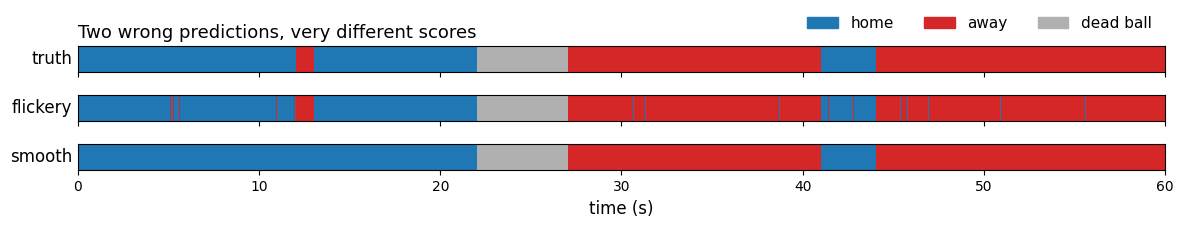

In [5]:
# extra code – this cell generates and saves the toy-example figure
ribbons([("truth", truth), ("flickery", flickery), ("smooth", smooth)],
        title="Two wrong predictions, very different scores", fig_id="toy_metric")

The flickery prediction gets about 98% of frames right, and yet its `spellF1` collapses: every
one-frame flip *cuts a true possession in two* and invents a tiny one in the middle. None of the
pieces overlaps its true possession enough to count.

The smooth prediction is wrong on only one second of frames, but the damage spreads: besides the
missed away possession, the two home possessions on either side are merged into one long prediction.
It can be matched to at most one of them, and only loosely (an IoU of 0.55, so it fails the stricter
thresholds).

> **Key insight.** `spellF1` scores the *segmentation*: where each possession starts and stops. A
> model that is good frame by frame is not enough. We need (1) no flicker and (2) the courage to
> declare short possessions when the evidence is there. Sections 5 and 6 are built around this.

**Two more things the challenge settles for us:**

* The ground truth is mechanical: it comes from corrected tracking, and possession changes at the
  **first touch** of the team taking over.
* `X` ("no answer") only matters outside the graded halves. Inside them, the ranking metric
  replaces an `X` with our previous label anyway, so we always answer `H`, `A` or `D`.

# 2. A first look at the provided match

The provided match is **automatic** tracking: positions of the players and of the ball, produced by
computer vision without any human correction. Let's load it. `matches.provided()` returns a
`Match`, the same container every source of data goes through in this project. Coordinates are in
metres and `NaN` means "not seen".

> **Note.** We only print aggregate statistics of the match data in this notebook, never raw rows:
> the data is licensed to participants.

In [6]:
prov = matches.provided()
graded = prov.period > 0
ball_seen = np.isfinite(prov.ball_xy[:, 0])
players_seen = (np.isfinite(prov.home_xy[:, :, 0]).sum(1) + np.isfinite(prov.away_xy[:, :, 0]).sum(1))

print(f"frames: {prov.n_frames:,} ({prov.n_frames / FPS / 60:.0f} min), graded: {graded.sum():,}")
print(f"halves (start, stop frame): {[(s, e) for _, s, e in prov.blocks()]}")
print(f"track slots: {prov.home_xy.shape[1]} home + {prov.away_xy.shape[1]} away (tracklets, not people)")
print(f"players visible per graded frame: mean {players_seen[graded].mean():.1f}, "
      f"5th percentile {np.percentile(players_seen[graded], 5):.0f}")
print(f"ball visible on {ball_seen[graded].mean():.1%} of graded frames")

frames: 199,319 (133 min), graded: 158,857
halves (start, stop frame): [(11185, 90652), (110808, 190198)]
track slots: 24 home + 22 away (tracklets, not people)
players visible per graded frame: mean 20.5, 5th percentile 14
ball visible on 59.3% of graded frames


The ball is **missing on about 41% of the graded frames**. That is the single most important fact
about this dataset. How is it missing: a frame here and there, or long stretches?

In [7]:
gaps = []
for _, s, e in prov.blocks():
    gaps += [b - a for a, b in degrade.runs(~ball_seen[s:e])]
gaps = np.array(gaps)
print(f"{len(gaps)} gaps; median gap {np.median(gaps) / FPS:.1f} s; "
      f"{gaps[gaps >= FPS].sum() / gaps.sum():.1%} of missing frames are in gaps of 1 s or more")

# What are the players doing while the ball is missing?
allxy = np.concatenate([prov.home_xy, prov.away_xy], 1)
v = features.central_velocity(allxy, 12)
med_speed = np.nanmedian(np.hypot(v[:, :, 0], v[:, :, 1]), 1)
print(f"median player speed: {np.nanmedian(med_speed[graded & ball_seen]):.2f} m/s with the ball visible, "
      f"{np.nanmedian(med_speed[graded & ~ball_seen]):.2f} m/s with the ball missing")

150 gaps; median gap 10.7 s; 99.9% of missing frames are in gaps of 1 s or more
median player speed: 1.62 m/s with the ball visible, 0.97 m/s with the ball missing


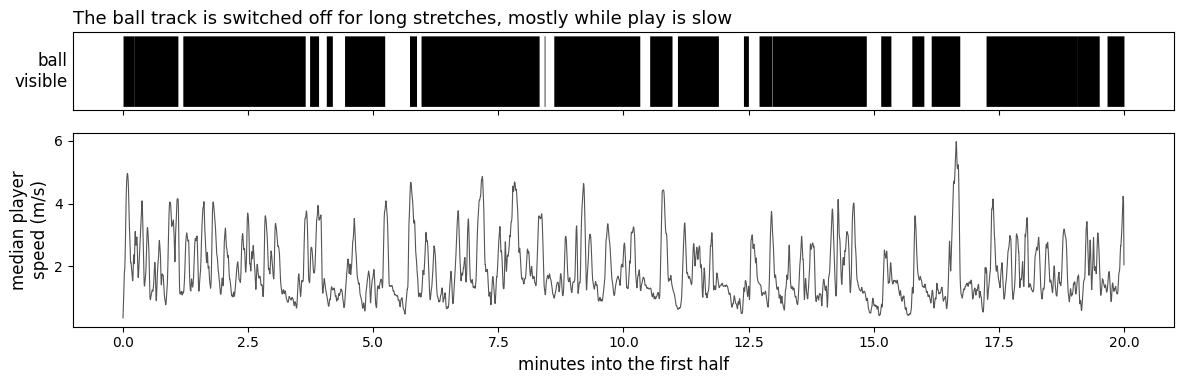

In [8]:
# extra code – this cell generates and saves the ball-visibility figure
_, s, e = prov.blocks()[0]
seg = slice(s, s + 20 * 60 * FPS)                          # first 20 minutes of the first half
t = np.arange(seg.stop - seg.start) / FPS / 60
fig, axes = plt.subplots(2, 1, figsize=(12, 4), sharex=True, gridspec_kw={"height_ratios": [1, 2.5]})
axes[0].fill_between(t, 0, ball_seen[seg], step="pre", color="k", lw=0)
axes[0].set_yticks([])
axes[0].set_ylabel("ball\nvisible", rotation=0, ha="right", va="center")
axes[0].set_title("The ball track is switched off for long stretches, mostly while play is slow", loc="left")
sm = np.convolve(np.nan_to_num(med_speed[seg]), np.ones(25) / 25, "same")
axes[1].plot(t, sm, lw=0.8, color="#555")
axes[1].set_ylabel("median player\nspeed (m/s)")
axes[1].set_xlabel("minutes into the first half")
save_fig("ball_visibility")
plt.show()

The track does not flicker: it is **switched off for long runs** (median gap about ten seconds),
and the players are usually slow when that happens. So "ball missing" is a strong hint of a dead
ball, but not a rule: in either direction it is sometimes wrong, and those are exactly the frames
that matter.

Two other defects, measured in `scripts/calibrate.py`:

* **The ball track is smoothed.** A kick, which is instantaneous, shows up as an acceleration bump
  about 0.8 s wide. So the tracked ball is *never quite at the kicker's feet* at the moment of a kick.
* **Players are tracklets, not people.** Tracks appear, vanish and swap identities. Every player
  feature we build is therefore a statistic over a *set* of players (nearest, median, spread...),
  never "player number 7".

> **Warning.** We have **no labels for this match**, and the rules forbid making any by hand. The
> five public minutes of ground truth may only be used to check that the pipeline works, not to
> train or tune. So: where do labels come from?

# 3. Labels from other games

Public tracking data with possession labels does exist, for *other* matches:

| source | matches | labels |
|---|---|---|
| DFL open dataset (Bassek et al., *Scientific Data* 2025, CC BY 4.0) | 7 Bundesliga matches | ball in play / not, and possessing team, on every frame |
| Metrica Sports sample data | 3 anonymised matches | derived by rule from the published events (`external/metrica_sample.py`) |

This gives about 1.4 million labelled frames. Let's load them and check that they describe the same
game as our challenge.

In [9]:
ext = matches.external()

def spells_of(label, period):
    # (start, stop, code) of every maximal run of H or A inside each half
    return metrics.spells(label, [(s, e) for _, s, e in pipeline.blocks_of(period)])

print(f"{'match':<18}{'frames':>9}{'possessions':>13}{'per minute':>12}{'< 1 s':>8}")
all_lengths = []
for m in ext:
    sp = spells_of(m.label, m.period)
    lengths = np.array([e - s for s, e, _ in sp]) / FPS
    all_lengths.append(lengths)
    minutes = (m.period > 0).sum() / FPS / 60
    print(f"{m.name:<18}{m.n_frames:>9,}{len(sp):>13}{len(sp) / minutes:>12.1f}{np.mean(lengths < 1):>8.0%}")
all_lengths = np.concatenate(all_lengths)

match                frames  possessions  per minute   < 1 s
dfl_J03WMX          145,967          511         5.3     17%
dfl_J03WN1          141,561          500         5.3     15%
dfl_J03WOH          137,214          402         4.4     11%
dfl_J03WOY          142,536          456         4.8      9%
dfl_J03WPY          146,211          421         4.3     14%
dfl_J03WQQ          142,345          401         4.2      9%
dfl_J03WR9          146,810          370         3.8     11%
metrica_sample_1    145,006          383         4.0     12%
metrica_sample_2    141,156          367         3.9     14%
metrica_sample_3    143,761          406         4.2     13%


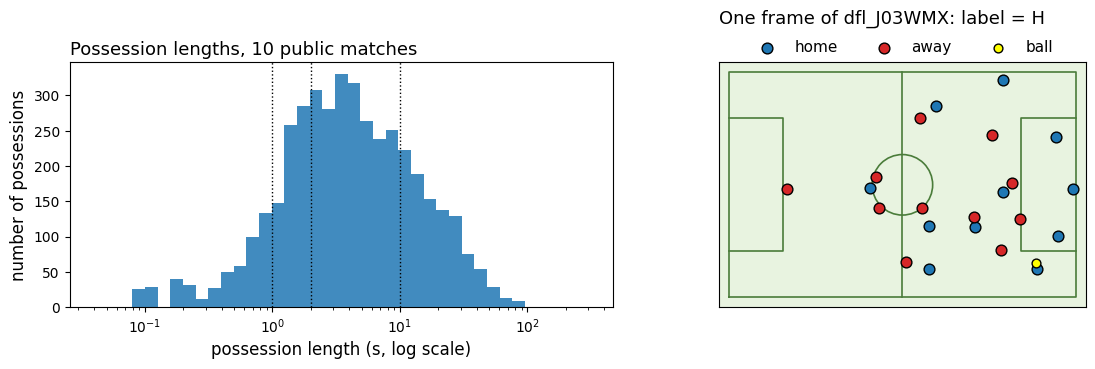

share of possessions under 1 s: 13%, under 2 s: 30%


In [10]:
# extra code – this cell generates and saves the possession-length figure
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.logspace(np.log10(0.04), np.log10(300), 40)
axes[0].hist(all_lengths, bins=bins, color="#1f77b4", alpha=0.85)
axes[0].set_xscale("log")
axes[0].set_xlabel("possession length (s, log scale)")
axes[0].set_ylabel("number of possessions")
axes[0].set_title("Possession lengths, 10 public matches", loc="left")
for x in (1, 2, 10):
    axes[0].axvline(x, color="k", ls=":", lw=1)

m = ext[0]
t = next(t for t in range(30000, m.n_frames) if m.label[t] == H and np.isfinite(m.ball_xy[t, 0])
         and (m.label[t - 50:t + 50] == H).all())
draw_pitch(axes[1], *m.pitch)
axes[1].scatter(*m.home_xy[t].T, s=60, c=COLORS["H"], edgecolor="k", label="home", zorder=2)
axes[1].scatter(*m.away_xy[t].T, s=60, c=COLORS["A"], edgecolor="k", label="away", zorder=2)
axes[1].scatter(*m.ball_xy[t], s=40, c="yellow", edgecolor="k", label="ball", zorder=3)
axes[1].legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.15), frameon=False)
axes[1].set_title(f"One frame of {m.name}: label = {LETTERS[m.label[t]]}", loc="left", pad=28)
save_fig("public_matches")
plt.show()
print(f"share of possessions under 1 s: {np.mean(all_lengths < 1):.0%}, under 2 s: {np.mean(all_lengths < 2):.0%}")

About 4 to 5 possessions per minute, and **almost a third of them last under two seconds**. Keep
that number in mind: short possessions are where the points are won and lost.

So we have labels, but for *clean* tracking: complete trajectories and a sharp ball that is always
there. A model trained on that would lean on signals that simply do not exist in our match. That
is the classic **train/test distribution shift** problem, and the next section is our answer to it.

# 4. Make the public matches look like ours

The idea is simple: **measure** how the provided tracking is degraded (without any label), then
**apply the same degradation** to the public matches before training. `degrade.degrade()` does four
things:

| defect | how we reproduce it |
|---|---|
| ball smoothing | Gaussian filter, σ = 7 frames, until kicks have the same width as in our match |
| ball position error | a slow random offset (0.25 m for DFL, 0.8 m for Metrica) |
| ball visibility | the **real** visible/missing masks of our match are cut into pieces and pasted onto public stoppages and live phases of similar length |
| players | random tracks are blanked for random stretches |

> **Tip.** Copying the visibility pattern instead of modelling it is the trick that makes this
> work. The question "how does the ball's disappearance relate to stoppages?" is answered by the
> provided match itself, not by assumptions we would have to guess.

To cut the masks we need to know roughly where our match's stoppages are. That first guess comes
from a model that **only looks at the players** (trained on public matches, no ball at all), so
that it shares nothing with the visibility it is used to cut (`scripts/bootstrap.py`). Let's
degrade one public match:

In [11]:
CACHE = Path(games.DATA_DIR) / ".cache"
bank = pipeline.load_bank(CACHE)
print(f"visibility bank: {len(bank['dead'])} stoppage masks, {len(bank['alive'])} live-play masks")

m = ext[0]
md_ = degrade.degrade(m, bank, seed=0)
inside = m.period > 0
print(f"{m.name}: ball visible {np.isfinite(m.ball_xy[inside, 0]).mean():.0%} before, "
      f"{np.isfinite(md_.ball_xy[inside, 0]).mean():.0%} after degradation")

visibility bank: 99 stoppage masks, 98 live-play masks
dfl_J03WMX: ball visible 100% before, 64% after degradation


Now let's zoom in on one kick, to see what smoothing does to the ball, and how we partly undo it.

A low-pass filter **cuts the corner** at every kick: at the instant of the kick, the smoothed ball
is somewhere inside the corner, not at the kicker's feet. But a little before and a little after
the kick, the ball moves in a straight line. So we can extend the incoming line forwards and the
outgoing line backwards: they meet near the true kick point. This is `features.desmooth()`.

In [12]:
v_clean = features.central_velocity(m.ball_xy, 2)
dv_clean = np.full(m.n_frames, np.nan)
dv_clean[6:-6] = np.hypot(*(v_clean[12:] - v_clean[:-12]).T)        # change of velocity over 0.5 s

v_deg = features.central_velocity(md_.ball_xy, 2)
q_deg, _ = features.desmooth(md_.ball_xy, v_deg)                     # de-smoothed position

# a clear pass: strong change of direction, live play, ball visible in the degraded track
kick = next(t for t in range(40000, m.n_frames - 40)
            if 9 < dv_clean[t] < 16 and dv_clean[t] == np.nanmax(dv_clean[t - 12:t + 13])
            and (m.label[t - 40:t + 40] < D).all() and np.isfinite(md_.ball_xy[t - 30:t + 30, 0]).all())
w = slice(kick - 25, kick + 26)
print("kick at frame", kick, "of", m.name)

kick at frame 41366 of dfl_J03WMX


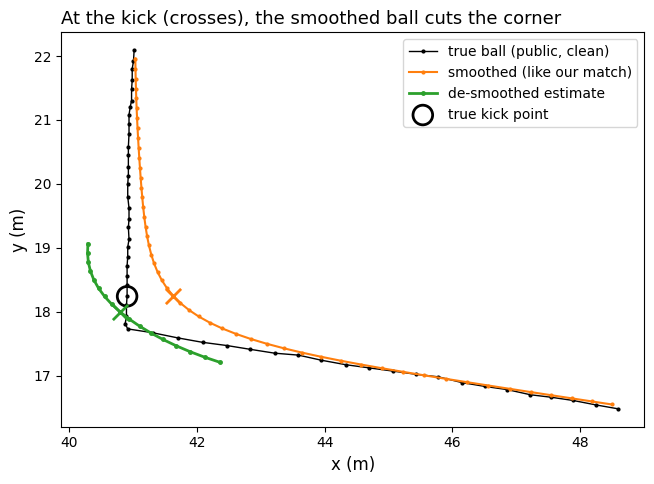

   smoothed: 0.72 m from the true kick point
de-smoothed: 0.27 m from the true kick point


In [13]:
# extra code – this cell generates and saves the de-smoothing figure
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(*m.ball_xy[w].T, "k.-", lw=1, ms=4, label="true ball (public, clean)")
ax.plot(*md_.ball_xy[w].T, ".-", color="#ff7f0e", lw=1.5, ms=4, label="smoothed (like our match)")
ax.plot(*q_deg[kick - 8:kick + 9].T, ".-", color="#2ca02c", lw=2, ms=5, label="de-smoothed estimate")
ax.scatter(*m.ball_xy[kick], s=200, facecolor="none", edgecolor="k", lw=2, label="true kick point", zorder=5)
ax.scatter(*md_.ball_xy[kick], s=120, marker="x", color="#ff7f0e", lw=2, zorder=5)
ax.scatter(*q_deg[kick], s=120, marker="x", color="#2ca02c", lw=2, zorder=5)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.legend(loc="best", fontsize=10)
ax.set_title("At the kick (crosses), the smoothed ball cuts the corner", loc="left")
save_fig("desmoothing")
plt.show()
for name, p in (("smoothed", md_.ball_xy[kick]), ("de-smoothed", q_deg[kick])):
    print(f"{name:>11}: {np.hypot(*(p - m.ball_xy[kick])):.2f} m from the true kick point")

Is the simulation realistic? We compare statistics that need **no label** between the provided
match and the degraded public matches, here the size of the ball's velocity changes and the share
of frames with a player within one metre of the ball. (`scripts/calibrate.py` has the full set.)

In [14]:
from calibrate import ball_stats

z = np.load(CACHE / "bootstrap.npz")
live_prov = np.zeros(prov.n_frames, bool)
live_prov[z["rows"]] = ~z["dead"]                       # label-free: the players-only guess

rows = {"provided match": ball_stats(prov, live_prov),
        f"{m.name}, as published": ball_stats(m, m.label < D),
        f"{m.name}, degraded": ball_stats(md_, m.label < D)}
for stat in ("velocity change over 0.5 s, pct 50/75/90/99", "share with a player within 1 m",
             "nearest-team switches per 1000 frames"):
    print(stat)
    for name, r in rows.items():
        print(f"    {name:<28} {r[stat]}")

velocity change over 0.5 s, pct 50/75/90/99
    provided match               [3.2, 5.8, 8.4, 14.7]
    dfl_J03WMX, as published     [3.3, 6.5, 12.7, 24.8]
    dfl_J03WMX, degraded         [2.7, 4.8, 7.4, 12.6]
share with a player within 1 m
    provided match               0.292
    dfl_J03WMX, as published     0.407
    dfl_J03WMX, degraded         0.275
nearest-team switches per 1000 frames
    provided match               22.3
    dfl_J03WMX, as published     24.3
    dfl_J03WMX, degraded         21.3


After degradation, the public match is much closer to ours: velocity changes are blurred in the same
way, and the ball is about as often next to a player. It is not perfect (the provided ball still has
slightly higher peaks), and we say so in the technical document.

There is a second, independent check: the organisers' baseline. It scores **0.243** `spellF1` on the
private full match, according to the organisers, and **0.248** on our degraded public matches
(**0.089** without the smoothing it relies on). Similar scores for the same simple method suggest
that our simulated matches are about as hard as the real one.

# 5. Features: what a frame looks like to the model

A machine-learning model does not see "a football match", it sees one row of numbers per frame.
`features.build()` computes **265 numbers per frame**, in three families. Each half is rotated so
that the home team always attacks to the right, and every window looks **both backwards and
forwards** in time (we label a finished match, so we are allowed to look into the "future").

| family | examples | mainly answers |
|---|---|---|
| **players** (148) | speed quantiles of each team, how many are standing still, team depth and width, distance between the two teams' centres | *is the ball alive?* (players stop when play stops) |
| **ball** (110) | distance from the ball to the nearest home / away player, a soft "control" score, recent and upcoming **touches** (sharp changes of velocity with a player close by), the same on the de-smoothed position | *which team has it?* |
| **visibility** (7) | is the ball missing, since when, until when | *is the ball alive?* |

Let's compute the features for our degraded match and check that a couple of them separate the
classes the way intuition says they should.

In [15]:
names, Xf, rows_ = features.build(md_)
lab = m.label[rows_]
col = {n: i for i, n in enumerate(names)}
print(f"feature table: {Xf.shape[0]:,} frames x {Xf.shape[1]} features")

feature table: 145,967 frames x 265 features


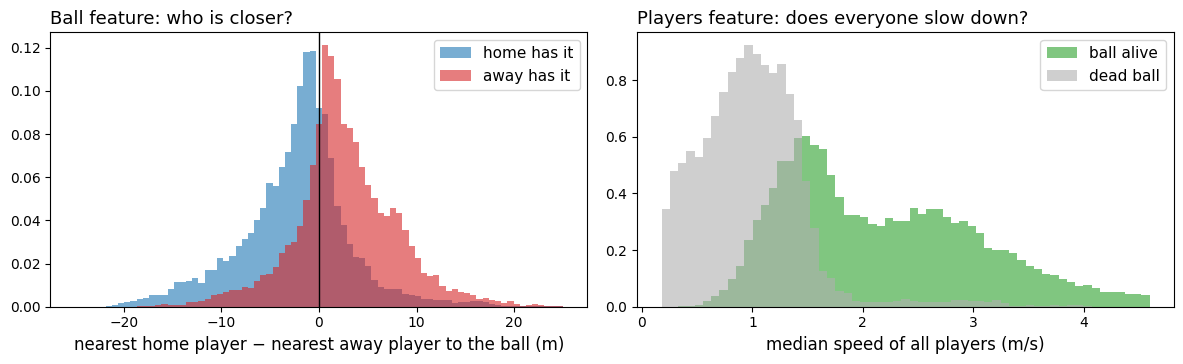

In [16]:
# extra code – this cell generates and saves the feature-intuition figure
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
f = Xf[:, col["b:d_diff"]]                                    # nearest home minus nearest away distance
bins = np.linspace(-25, 25, 80)
for k, name in ((H, "home has it"), (A, "away has it")):
    axes[0].hist(f[lab == k], bins=bins, alpha=0.6, density=True, color=COLORS[LETTERS[k]], label=name)
axes[0].axvline(0, color="k", lw=1)
axes[0].set_xlabel("nearest home player − nearest away player to the ball (m)")
axes[0].set_title("Ball feature: who is closer?", loc="left")
axes[0].legend()

speed_col = "p:all_sp_med"                                 # median speed of all players
g = Xf[:, col[speed_col]]
bins = np.linspace(np.nanpercentile(g, 1), np.nanpercentile(g, 99), 60)
axes[1].hist(g[lab < D], bins=bins, alpha=0.6, density=True, color="#2ca02c", label="ball alive")
axes[1].hist(g[lab == D], bins=bins, alpha=0.6, density=True, color=COLORS["D"], label="dead ball")
axes[1].set_xlabel("median speed of all players (m/s)")
axes[1].set_title("Players feature: does everyone slow down?", loc="left")
axes[1].legend()
save_fig("feature_intuition")
plt.show()

Each feature on its own is a weak, overlapping signal: there are plenty of frames where the
nearest player belongs to the team *without* the ball (think of a pressing defender). Combining
hundreds of such weak signals is exactly what the next step is for.

# 6. Models: gradient-boosted trees

We use **LightGBM**, a gradient-boosted decision tree library. Intuitively:

* a single decision tree asks a series of yes/no questions ("is the nearest home player closer
  than 2 m?", "did the ball change direction in the last 0.5 s?") and outputs a probability;
* *boosting* trains hundreds of small trees one after the other, each one focusing on the mistakes
  of the trees before it. The sum of all of them is a strong, well-calibrated classifier.

Trees are a good fit here: they are fast on a laptop CPU, they cope with missing values natively
(our `NaN`s when the ball is gone), and they don't need the features to be scaled.

We train **five** binary classifiers (`pipeline.train()` and `pipeline.train_events()`):

| model | question | trained on |
|---|---|---|
| `alive` | is the ball dead? | every frame; sees players + visibility + ball position vs. the lines only |
| `team` | does home have it? | live frames only; sees everything |
| `event_team`, `event_stop`, `event_restart` | does a change of team / a stoppage / a restart happen *right here* (±2 frames)? | as above |

Two training details that matter:

* **Every match is used twice, with home and away swapped**, so the model cannot prefer a side.
* **Frames are weighted by (length of their possession)^−0.5.** Without it, one possession of
  one minute outvotes sixty possessions of one second, while the metric counts each of them once.

> **Note.** Training takes about 7 minutes on 8 CPU cores (`python scripts/train.py`). This notebook
> loads the trained models from `models/` instead of training them again.

Let's look at what the `team` and `alive` models rely on most:

In [17]:
feature_names = json.load(open(ROOT / "models" / "features.json"))
alive_model = models.load(str(ROOT / "models" / "alive.txt"))
team_model = models.load(str(ROOT / "models" / "team.txt"))

def top_features(booster, cols, k=12):
    gain = booster.feature_importance("gain")
    share = gain / gain.sum()
    order = np.argsort(share)[::-1][:k]
    return [feature_names[cols[i]] for i in order], share[order]

tops = {"team model": top_features(team_model, models.team_columns(feature_names)),
        "alive model": top_features(alive_model, models.alive_columns(feature_names))}

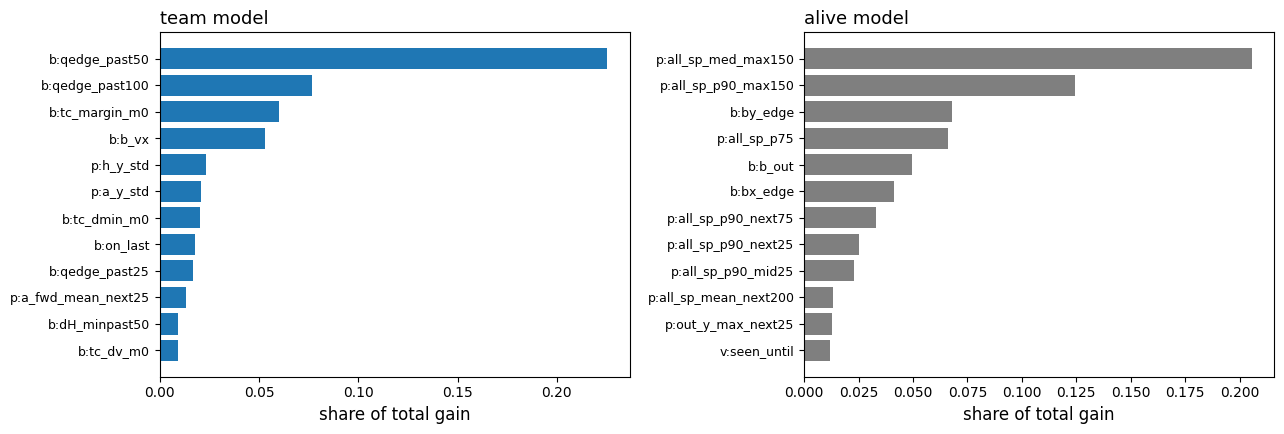

In [18]:
# extra code – this cell generates and saves the feature-importance figure
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (title, (n, s)) in zip(axes, tops.items()):
    ax.barh(range(len(n))[::-1], s, color="#1f77b4" if "team" in title else "#7f7f7f")
    ax.set_yticks(range(len(n))[::-1])
    ax.set_yticklabels(n, fontsize=9)
    ax.set_xlabel("share of total gain")
    ax.set_title(title, loc="left")
save_fig("feature_importance")
plt.show()

Feature names start with `b:` (ball), `p:` (players) or `v:` (visibility). The team model leans
on ball-control features computed on the **de-smoothed** position (the `q`-family) and on the touch
chain, which is what the ground truth's "first touch" definition suggests. The alive model leans on
how the players move and on the visibility of the ball track.

## Validating honestly: cross-validation across matches

To know how well this works on a match the model has **never seen**, we use 3-fold
cross-validation **grouped by match**: each fold trains on 6 or 7 public matches and predicts the
held-out ones, after degrading them exactly like the provided match (`scripts/run_cv.py`).
Splitting by frame instead would be cheating, because neighbouring frames are near-duplicates.

The resulting *out-of-fold* probabilities are saved in `experiments/oof_v3.npz`. Let's look at
two minutes of one held-out match:

In [19]:
from tune_decoder import load_oof

oof = load_oof("v3")
params = dec.DecoderParams(*json.load(open(ROOT / "models" / "decoder.json"))["params"])
print(f"{len(oof)} held-out matches:", ", ".join(oof))

name = "metrica_sample_1"
p_dead, p_home, label, period, p_ev = oof[name]
blocks = pipeline.blocks_of(period)

# For the figures, pick a two-minute window that shows the typical failure of a frame-by-frame
# reading (it flickers) while the decoded sequence has about the right number of changes. It is an
# illustration only: the honest numbers are the averages over all ten matches below.
argmax = np.where(p_dead > 0.5, D, np.where(p_home > 0.5, H, A)).astype(np.int8)
viterbi = dec.decode(p_dead.astype(float), p_home.astype(float), blocks, params, p_events=p_ev.astype(float))
n_changes = lambda x: int((np.diff(x) != 0).sum())
L = 120 * FPS
cands = [s for _, b0, b1 in blocks for s in range(b0, b1 - L, 5 * FPS)
         if abs(n_changes(viterbi[s:s + L]) - n_changes(label[s:s + L])) <= 2 and n_changes(label[s:s + L]) >= 10]
start = max(cands, key=lambda s: n_changes(argmax[s:s + L]))
win = slice(start, start + L)
print(f"window {start / FPS:.0f}-{(start + L) / FPS:.0f} s: label changes truth {n_changes(label[win])}, "
      f"argmax {n_changes(argmax[win])}, Viterbi {n_changes(viterbi[win])}")

10 held-out matches: dfl_J03WMX, dfl_J03WN1, dfl_J03WOH, dfl_J03WOY, dfl_J03WPY, dfl_J03WQQ, dfl_J03WR9, metrica_sample_1, metrica_sample_2, metrica_sample_3
window 4891-5011 s: label changes truth 13, argmax 53, Viterbi 11


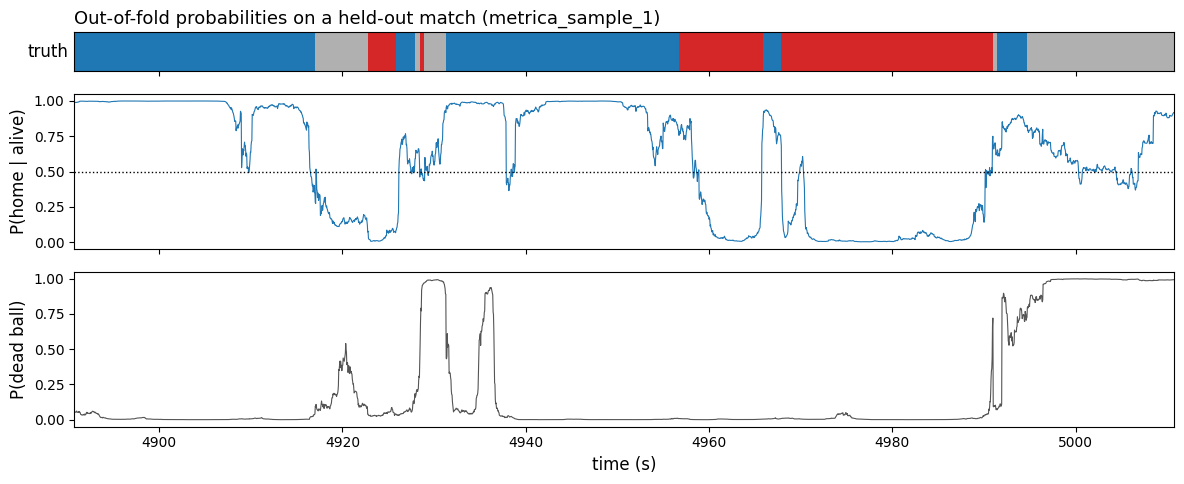

In [20]:
# extra code – this cell generates and saves the probabilities figure
t = np.arange(win.start, win.stop) / FPS
fig, axes = plt.subplots(3, 1, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [0.5, 2, 2]})
ribbon(axes[0], label[win], win.start, "truth")
axes[1].plot(t, p_home[win], color=COLORS["H"], lw=0.8)
axes[1].axhline(0.5, color="k", ls=":", lw=1)
axes[1].set_ylabel("P(home | alive)")
axes[2].plot(t, p_dead[win], color="#555", lw=0.8)
axes[2].set_ylabel("P(dead ball)")
axes[2].set_xlabel("time (s)")
axes[0].set_title(f"Out-of-fold probabilities on a held-out match ({name})", loc="left")
save_fig("probabilities")
plt.show()

The probabilities follow the truth well, but they are **noisy**: they hover around 0.5 during
contested phases and cross it back and forth. Section 1 told us exactly what that does to the
ranking metric.

# 7. From probabilities to possessions: the Viterbi decoder

The obvious approach is to take the most likely label on each frame (*argmax*). The organisers'
baseline adds a *majority vote* over a sliding window to smooth it. Both treat each frame (or
window) on its own.

We instead treat the match as a **hidden Markov model** with three states (`H`, `A`, `D`):

* on every frame, each state earns the (log-)probability our models give it;
* each **switch** of state pays a fee. There are three different fees: a change of team (cheap, it
  happens all the time and can be brief), a stoppage (expensive), and a restart;
* the fee for a change of team is **lowered on frames where the event detector saw a touch**,
  and raised elsewhere.

The **Viterbi algorithm** finds, exactly, the single sequence of labels with the best total score
over a whole half. A short possession survives if the evidence for it pays for the two switches it
needs. There is no minimum duration and no smoothing window. The seven numbers (fees, gains and a
"temper" that discounts correlated frames) are chosen by `spellF1` on the held-out public matches
(`scripts/tune_decoder.py`), never on the provided match.

Let's compare the three on the same two minutes:

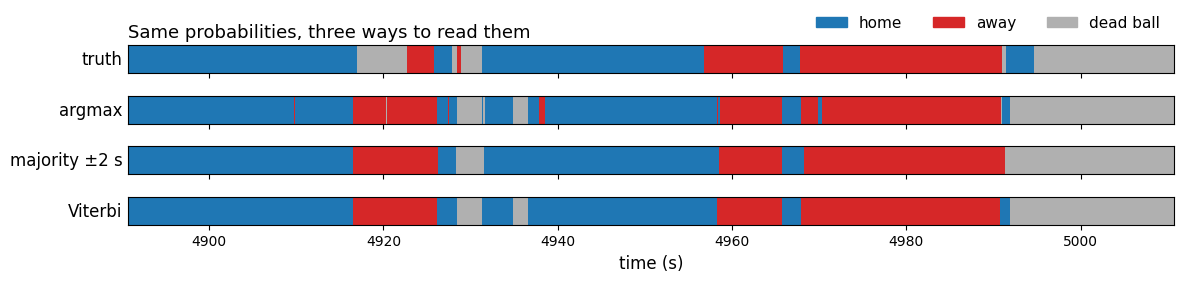

In [21]:
# argmax and viterbi were computed above, when choosing the window
vote = dec.majority_smooth(argmax, blocks, 50)                          # baseline-style, ±2 s

ribbons([("truth", label[win]), ("argmax", argmax[win]), ("majority ±2 s", vote[win]),
         ("Viterbi", viterbi[win])], t0=win.start,
        title="Same probabilities, three ways to read them", fig_id="decoders")

Argmax flickers, the majority vote erases the short possessions, and Viterbi keeps the sharp
changes without the flicker. Now on **all ten held-out matches**, scored with the organisers'
own scorer:

In [22]:
def score_match(label, period, pred):
    gt, cut = pipeline.table_gt({"label": label, "period": period})
    return pipeline.score(gt, pipeline.with_gap(pred, cut))

results = {"argmax": [], "majority ±2 s": [], "Viterbi (submitted)": []}
for name, (pd_, ph, lab, per, pe) in oof.items():
    b = pipeline.blocks_of(per)
    am = np.where(pd_ > 0.5, D, np.where(ph > 0.5, H, A)).astype(np.int8)
    results["argmax"].append(score_match(lab, per, am))
    results["majority ±2 s"].append(score_match(lab, per, dec.majority_smooth(am, b, 50)))
    results["Viterbi (submitted)"].append(score_match(
        lab, per, dec.decode(pd_.astype(float), ph.astype(float), b, params, p_events=pe.astype(float))))

print(f"{'decoder':<22}{'spellF1':>9}{'macroF1':>9}")
for k, rs in results.items():
    print(f"{k:<22}{np.mean([r['spell_f1'] for r in rs]):>9.3f}{np.mean([r['macro_f1'] for r in rs]):>9.3f}")

decoder                 spellF1  macroF1
argmax                    0.414    0.908
majority ±2 s             0.599    0.906
Viterbi (submitted)       0.659    0.915


Same models, same probabilities, same per-frame accuracy (`macroF1` barely moves), but the
ranking metric goes from about 0.41 to about 0.66 just by **reading the probabilities as a
sequence**. That is the biggest single gain in the project.

How sensitive is it to the team-change fee? Let's sweep it. A low fee means many switches (flicker),
a high fee means few (missed short possessions):

In [23]:
fees = [0.5, 1, 2, 3, 4.5, 6.5, 9, 13]
sweep = [dec.DecoderParams(params[0], c, *params[2:]) for c in fees]
spell, n_pred, n_true = np.zeros(len(fees)), np.zeros(len(fees)), 0
for name, (pd_, ph, lab, per, pe) in oof.items():
    b = pipeline.blocks_of(per)
    runs = [(s, e) for _, s, e in b]
    gts = metrics.spells(lab, runs)
    n_true += len(gts)
    paths = dec.decode_batch(pd_.astype(float), ph.astype(float), b, sweep, p_events=pe.astype(float))
    for i, path in enumerate(paths):
        ps = metrics.spells(path, runs)
        spell[i] += metrics.spell_f1(gts, ps) / len(oof)
        n_pred[i] += len(ps)

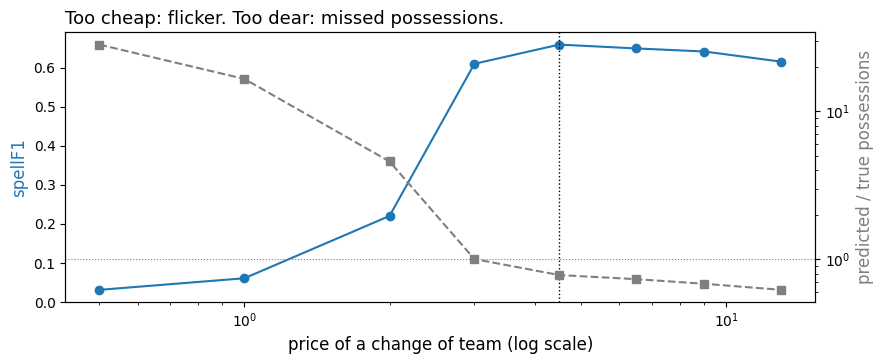

fee  0.5: spellF1 0.031, predicted/true possessions 28.23
fee    1: spellF1 0.061, predicted/true possessions 16.55
fee    2: spellF1 0.221, predicted/true possessions 4.59
fee    3: spellF1 0.610, predicted/true possessions 1.01
fee  4.5: spellF1 0.659, predicted/true possessions 0.78
fee  6.5: spellF1 0.649, predicted/true possessions 0.74
fee    9: spellF1 0.642, predicted/true possessions 0.69
fee   13: spellF1 0.616, predicted/true possessions 0.62


In [24]:
# extra code – this cell generates and saves the fee-sweep figure
fig, ax1 = plt.subplots(figsize=(9, 3.8))
ax1.plot(fees, spell, "o-", color="#1f77b4")
ax1.set_xscale("log")
ax1.set_xlabel("price of a change of team (log scale)")
ax1.set_ylabel("spellF1", color="#1f77b4")
ax2 = ax1.twinx()
ax2.plot(fees, n_pred / n_true, "s--", color="#7f7f7f")
ax2.set_yscale("log")
ax2.axhline(1, color="#7f7f7f", lw=0.8, ls=":")
ax2.set_ylabel("predicted / true possessions", color="#7f7f7f")
ax1.axvline(params.cost_team, color="k", lw=1, ls=":")
ax1.set_title("Too cheap: flicker. Too dear: missed possessions.", loc="left")
save_fig("fee_sweep")
plt.show()
for c, sf, r in zip(fees, spell, n_pred / n_true):
    print(f"fee {c:>4}: spellF1 {sf:.3f}, predicted/true possessions {r:.2f}")

The classic bias–variance trade-off, in a football costume. The best fee sits where we predict
**about a fifth fewer possessions than there really are** (0.78 of the true count). Below that
fee, flicker appears very fast. Above it, possessions are missed. Since the evidence for very
short possessions is weak, leaving them out is the safer bet.

# 8. Where do we still lose points?

A useful question to ask about any pipeline: *if one component were perfect, how much would we
gain?* We replace one model's probabilities by the truth, decode again, and look at the score.

In [25]:
from error_analysis import matched, BINS

oracle = {"as predicted": [], "perfect alive/dead": [], "perfect team": []}
by_len = {b: [0, 0] for b in BINS}                           # [true possessions, recovered at IoU 0.5]
for name, (pd_, ph, lab, per, pe) in oof.items():
    b = pipeline.blocks_of(per)
    runs = [(s, e) for _, s, e in b]
    gts = metrics.spells(lab, runs)
    pe = pe.astype(float)
    pred = dec.decode(pd_.astype(float), ph.astype(float), b, params, p_events=pe)
    perfect_dead = np.where(lab == D, 1 - 1e-6, 1e-6)
    perfect_home = np.where(lab == H, 1 - 1e-6, np.where(lab == A, 1e-6, 0.5))
    for key, path in (("as predicted", pred),
                      ("perfect alive/dead", dec.decode(perfect_dead, ph.astype(float), b, params, p_events=pe)),
                      ("perfect team", dec.decode(pd_.astype(float), perfect_home, b, params, p_events=pe))):
        oracle[key].append(metrics.spell_f1(gts, metrics.spells(path, runs)))
    hit, _ = matched(gts, metrics.spells(pred, runs), 0.5)
    for i, (s, e, _) in enumerate(gts):
        for lo, hi in BINS:
            if lo <= e - s < hi:
                by_len[(lo, hi)][0] += 1
                by_len[(lo, hi)][1] += i in hit

for k, v in oracle.items():
    print(f"{k:<20} spellF1 {np.mean(v):.3f}")

as predicted         spellF1 0.659
perfect alive/dead   spellF1 0.711
perfect team         spellF1 0.937


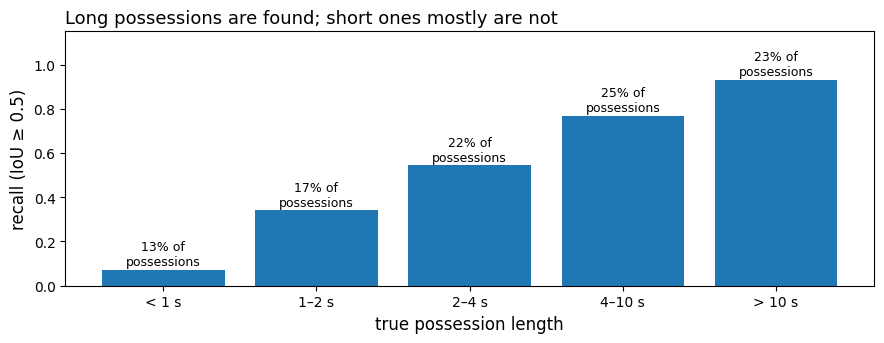

In [26]:
# extra code – this cell generates and saves the recall-by-length figure
labels_ = ["< 1 s", "1–2 s", "2–4 s", "4–10 s", "> 10 s"]
n = np.array([by_len[b][0] for b in BINS])
rec = np.array([by_len[b][1] for b in BINS]) / n
fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.bar(labels_, rec, color="#1f77b4")
for bar, share in zip(bars, n / n.sum()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02, f"{share:.0%} of\npossessions",
            ha="center", fontsize=9)
ax.set_ylim(0, 1.15)
ax.set_ylabel("recall (IoU ≥ 0.5)")
ax.set_xlabel("true possession length")
ax.set_title("Long possessions are found; short ones mostly are not", loc="left")
save_fig("recall_by_length")
plt.show()

The diagnosis is clear:

* A perfect alive/dead call would add only about **5 points**. Stoppages are mostly solved.
* A perfect team call would add almost **30 points**. That is where the remaining error is.
* Inside the team call, the problem is **short possessions**: we find almost every possession
  longer than 10 seconds and very few under 1 second.

This matches the defect we saw in section 2: a ball smoothed over 0.8 s, and missing 41% of the
time, simply cannot show a one-frame touch clearly. Getting past that would take a sharper ball,
for example by detecting it in the video (see the conclusion).

# 9. The real match: BAR-ATH

Everything is now in place. `scripts/predict.py` chains the steps on the provided match:

1. build the 265 features (on the tracking as it is: it is *already* degraded);
2. run the five models;
3. find the **opening kickoff** of each half. The second graded half starts almost two minutes
   before its kickoff, with players passing a ball around, which a model would happily call
   "play". `kickoff.py` detects the moment when the teams stop standing in their own halves, which
   is true of every kickoff;
4. Viterbi, half by half.

In [27]:
from predict import predict

codes, probs, rows_prov = predict(prov)
print(f"frames forced to D before an opening kickoff: {int(probs['pre_kickoff'].sum()):,}")
for half, s, e in prov.blocks():
    sp = metrics.spells(codes, [(s, e)])
    lens = np.array([b - a for a, b, _ in sp]) / FPS
    print(f"half {half}: H {np.mean(codes[s:e] == H):.0%} · A {np.mean(codes[s:e] == A):.0%} · "
          f"D {np.mean(codes[s:e] == D):.0%} | {len(sp)} possessions "
          f"({len(sp) / ((e - s) / FPS / 60):.1f} per minute, median {np.median(lens):.1f} s)")

frames forced to D before an opening kickoff: 2,946
half 1: H 34% · A 20% · D 46% | 142 possessions (2.7 per minute, median 7.4 s)
half 2: H 29% · A 23% · D 48% | 168 possessions (3.2 per minute, median 6.2 s)


Barcelona has the ball more than Athletic, which is what anyone who watched this match would
expect. But we predict only about 3 possessions per minute, against 3.8 to 5.3 in the public
matches. That gap is the same weakness seen in sections 7 and 8, and it is probably larger here:
many of the shortest possessions are missed, and the real match is noisier than our simulation.

## The public five minutes: a pipeline check, not a target

The organisers published the ground truth for the first five minutes of play. We use it **only to
check that nothing is broken** (frame alignment, team orientation, kickoff handling). Nothing in
the repository reads this score back to choose anything.

> **Warning.** With only 17 possessions, this number is very noisy (the scorer's own bootstrap
> interval is about 0.53–0.89). It says "the pipeline works", not "this is our score".

public window: spellF1 0.735 · macroF1 0.929 · alive/dead F1 0.982 · possessions 14 predicted vs 17 true


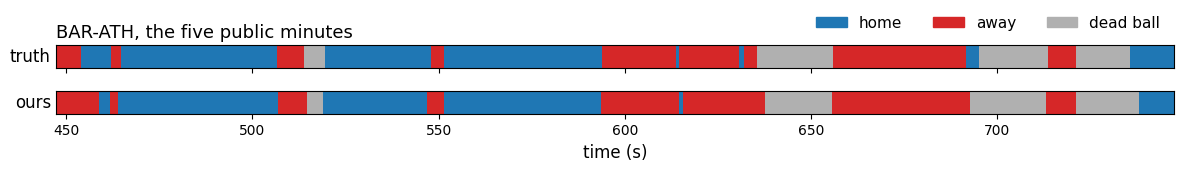

In [28]:
gt_public = pipeline.pm.label_codes(pipeline.pm.read_label_csv(
    str(ROOT / "evaluation" / "gt" / "BAR-ATH_possession_gt_public.csv")))
r = pipeline.score(gt_public, codes)
print(f"public window: spellF1 {r['spell_f1']:.3f} · macroF1 {r['macro_f1']:.3f} · "
      f"alive/dead F1 {r['alive_dead_f1']:.3f} · possessions {r['n_pred_spells']} predicted vs {r['n_gt_spells']} true")

scored = np.flatnonzero(gt_public != X)
win = slice(scored[0], scored[-1] + 1)
ribbons([("truth", gt_public[win]), ("ours", codes[win])], t0=win.start,
        title="BAR-ATH, the five public minutes", fig_id="public_window")

The long possessions and stoppages line up, and the changes of team happen at the right moments
(no time offset). The differences are, once again, the very short possessions.

Finally, the submission file:

In [29]:
out = ROOT / "evaluation" / "results" / "wa_barca.csv"
pipeline.write_submission(str(out), codes)
print(f"wrote {out.relative_to(ROOT)}: {len(codes):,} rows",
      {k: int((codes == i).sum()) for i, k in enumerate("HADX")})

wrote evaluation/results/wa_barca.csv: 199,319 rows {'H': 49897, 'A': 33956, 'D': 75004, 'X': 40462}


In [30]:
!cd .. && python evaluation/validate_submission.py evaluation/results/wa_barca.csv

OK    wa_barca.csv
      199319 rows, frame 0..199318

      label counts
        H    49897   25.0%
        A    33956   17.0%
        D    75004   37.6%
        X    40462   20.3%

      reports 310 possessions of mean 10.8 s
      (counted with each X as a gap; the scorer bridges abstentions inside a real
       possession, so its count can be lower than this one)

Valid. Note this checks the format only -- it says nothing about whether the labels are right.
Score it against the public ground truth with run_evaluation.py.


# 10. Summary

| step | what it does | why |
|---|---|---|
| labels from other games | 10 public matches, 1.4 M frames | no hand labels allowed on the provided match |
| degradation | smoothing, visibility masks copied from our match, track loss | train on data that looks like the data we predict on |
| features | 265 per frame, players / ball / visibility, two-sided windows, de-smoothed ball | robust to anonymous tracklets and missing balls |
| models | 5 LightGBM classifiers, side-swapped, possession-weighted | fast on a CPU, handle `NaN`s, no scaling |
| decoder | 3-state HMM, Viterbi, event-aware switch fees | the metric scores possessions, not frames |
| validation | grouped cross-validation on held-out public matches | the provided match's labels are off-limits |

**Results on held-out public matches** (organisers' scorer):

| system | spellF1 | macroF1 |
|---|---|---|
| organisers' baseline, ±50 frames | 0.248 | 0.652 |
| our models + argmax | 0.41 | 0.91 |
| our models + Viterbi (**submitted**) | **0.659** | **0.915** |
| … with a perfect team call (upper bound) | 0.94 | – |

**What we learned**

* Choosing the decoder for the metric mattered more than any model change.
* Measuring the defects of the provided data, and copying them onto the training data, is what
  lets labels from other games transfer to this one.
* Short possessions are the remaining frontier, and they are limited by the ball track itself.

**What we would do next**

1. **Detect the ball in the tactical video.** A sharp, frame-accurate ball would reveal the touches
   that the smoothed track hides. This targets the error we measured in section 8.
2. **Replace or stack the trees with a temporal convolutional network** (`scripts/run_tcn.py`). It
   was slightly better on one fold (+0.012), which is within the noise of the metric, so it was not
   submitted.
3. **Refine the simulation** where it is still off (the provided ball's highest speeds).

See `docs/TECHNICAL.md` for the complete technical document.